In [1]:
# ============================================================
# NOTEBOOK 03
# DEEP LEARNING RUL PREDICTION
# ============================================================
# Main goals:
# 1. Load leakage-free processed engine data
# 2. Create temporal sequences
# 3. Train a BiLSTM baseline
# 4. Evaluate it fairly on unseen validation engines
# ============================================================

import os
import joblib

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

print("Notebook 03 basic libraries loaded successfully.")

Notebook 03 basic libraries loaded successfully.


In [2]:
# ============================================================
# LOAD NOTEBOOK 02 DEEP LEARNING CHECKPOINT
# ============================================================

DL_CHECKPOINT_PATH = (
    r"D:\IST\Aircraft_Engine_RUL"
    r"\checkpoints\phase_02_deep_learning_checkpoint.joblib"
)

# Safety check
if not os.path.exists(DL_CHECKPOINT_PATH):
    raise FileNotFoundError(
        f"Checkpoint not found:\n{DL_CHECKPOINT_PATH}"
    )

# Load checkpoint
dl_checkpoint = joblib.load(
    DL_CHECKPOINT_PATH
)

print("Deep Learning checkpoint loaded successfully.")
print("Saved objects:", len(dl_checkpoint))

Deep Learning checkpoint loaded successfully.
Saved objects: 20


In [3]:
# ============================================================
# RESTORE ENGINE-WISE DATA
# ============================================================

# FD002
fd002_train_model = dl_checkpoint[
    "fd002_train_model"
].copy()

fd002_val_model = dl_checkpoint[
    "fd002_val_model"
].copy()


# FD003
fd003_train_model = dl_checkpoint[
    "fd003_train_model"
].copy()

fd003_val_model = dl_checkpoint[
    "fd003_val_model"
].copy()


# ============================================================
# RESTORE SENSOR INFORMATION
# ============================================================

candidate_sensor_cols = dl_checkpoint[
    "candidate_sensor_cols"
]

model_sensor_cols = dl_checkpoint[
    "model_sensor_cols"
]

ranked_sensors = dl_checkpoint[
    "ranked_sensors"
]


print("FD002 Train:", fd002_train_model.shape)
print("FD002 Val  :", fd002_val_model.shape)

print("\nFD003 Train:", fd003_train_model.shape)
print("FD003 Val  :", fd003_val_model.shape)

print("\nModel Sensor Columns:")
print(model_sensor_cols)

FD002 Train: (43464, 66)
FD002 Val  : (10295, 66)

FD003 Train: (20012, 65)
FD003 Val  : (4708, 65)

Model Sensor Columns:
['sensor_2_model_norm', 'sensor_3_model_norm', 'sensor_4_model_norm', 'sensor_6_model_norm', 'sensor_7_model_norm', 'sensor_8_model_norm', 'sensor_9_model_norm', 'sensor_10_model_norm', 'sensor_11_model_norm', 'sensor_12_model_norm', 'sensor_13_model_norm', 'sensor_14_model_norm', 'sensor_15_model_norm', 'sensor_17_model_norm', 'sensor_20_model_norm', 'sensor_21_model_norm']


In [4]:
# ============================================================
# SORT DATA CHRONOLOGICALLY
# ============================================================
# Every engine must remain internally ordered by cycle.
# ============================================================

fd002_train_model = (
    fd002_train_model
    .sort_values(
        ["engine_id", "cycle"]
    )
    .reset_index(drop=True)
)

fd002_val_model = (
    fd002_val_model
    .sort_values(
        ["engine_id", "cycle"]
    )
    .reset_index(drop=True)
)

fd003_train_model = (
    fd003_train_model
    .sort_values(
        ["engine_id", "cycle"]
    )
    .reset_index(drop=True)
)

fd003_val_model = (
    fd003_val_model
    .sort_values(
        ["engine_id", "cycle"]
    )
    .reset_index(drop=True)
)

print("Datasets sorted by engine_id and cycle.")

Datasets sorted by engine_id and cycle.


In [5]:
# ============================================================
# VERIFY DEEP LEARNING INPUT COLUMNS
# ============================================================

required_columns = (
    ["engine_id", "cycle", "RUL_capped"]
    + model_sensor_cols
)


def validate_sequence_columns(
    df,
    dataset_name
):
    """
    Confirm that all sequence-model columns exist.
    """

    missing = [
        col
        for col in required_columns
        if col not in df.columns
    ]

    if len(missing) == 0:
        print(
            f"✅ {dataset_name}: "
            "all required columns available."
        )

    else:
        print(
            f"❌ {dataset_name}: missing columns"
        )

        print(missing)


validate_sequence_columns(
    fd002_train_model,
    "FD002 Train"
)

validate_sequence_columns(
    fd002_val_model,
    "FD002 Validation"
)

validate_sequence_columns(
    fd003_train_model,
    "FD003 Train"
)

validate_sequence_columns(
    fd003_val_model,
    "FD003 Validation"
)

✅ FD002 Train: all required columns available.
✅ FD002 Validation: all required columns available.
✅ FD003 Train: all required columns available.
✅ FD003 Validation: all required columns available.


In [6]:
# ============================================================
# CREATE SLIDING WINDOW SEQUENCES
# ============================================================
# IMPORTANT:
# Sequences are created separately within each engine.
#
# A window is NEVER allowed to cross from one engine
# into another engine.
# ============================================================

def create_sequences(
    df,
    feature_cols,
    sequence_length=30,
    target_col="RUL_capped"
):
    """
    Convert engine-wise tabular time-series data into
    fixed-length sequential samples.

    Parameters
    ----------
    df:
        Engine-wise DataFrame.

    feature_cols:
        Sensor columns used as sequence inputs.

    sequence_length:
        Number of historical cycles per sample.

    target_col:
        RUL value predicted at the final timestep
        of each sequence.

    Returns
    -------
    X:
        Shape = (samples, sequence_length, features)

    y:
        RUL target for each sequence.

    metadata:
        Engine ID and cycle corresponding to each target.
        Useful later for validation and plotting.
    """

    X_sequences = []
    y_sequences = []

    metadata = []

    # Process each engine independently
    for engine_id, engine_data in df.groupby(
        "engine_id"
    ):

        # Ensure chronological order
        engine_data = (
            engine_data
            .sort_values("cycle")
            .reset_index(drop=True)
        )

        # Extract only sensor inputs
        feature_values = (
            engine_data[
                feature_cols
            ]
            .to_numpy(
                dtype=np.float32
            )
        )

        # Extract target values
        target_values = (
            engine_data[
                target_col
            ]
            .to_numpy(
                dtype=np.float32
            )
        )

        cycle_values = (
            engine_data[
                "cycle"
            ]
            .to_numpy()
        )

        # Skip engines shorter than the requested sequence
        if len(engine_data) < sequence_length:
            continue

        # Sliding-window generation
        for end_idx in range(
            sequence_length - 1,
            len(engine_data)
        ):

            # Starting index of current sequence
            start_idx = (
                end_idx
                - sequence_length
                + 1
            )

            # Current sequence
            sequence = feature_values[
                start_idx:end_idx + 1
            ]

            # Target is RUL at final sequence timestep
            target = target_values[
                end_idx
            ]

            X_sequences.append(
                sequence
            )

            y_sequences.append(
                target
            )

            # Store mapping for later analysis
            metadata.append({
                "engine_id": engine_id,
                "cycle": cycle_values[end_idx]
            })

    # Convert Python lists into NumPy arrays
    X_sequences = np.asarray(
        X_sequences,
        dtype=np.float32
    )

    y_sequences = np.asarray(
        y_sequences,
        dtype=np.float32
    )

    metadata = pd.DataFrame(
        metadata
    )

    return (
        X_sequences,
        y_sequences,
        metadata
    )

In [7]:
SEQUENCE_LENGTH = 30

In [8]:
# ============================================================
# INITIAL SEQUENCE LENGTH
# ============================================================
# 30 cycles is our first controlled baseline.
# Later we will compare multiple sequence lengths.
# ============================================================

SEQUENCE_LENGTH = 30

print(
    "Initial Sequence Length:",
    SEQUENCE_LENGTH
)

Initial Sequence Length: 30


In [9]:
# ============================================================
# FD002 TRAINING SEQUENCES
# ============================================================

X_seq_train_fd002, y_seq_train_fd002, meta_train_fd002 = (
    create_sequences(
        fd002_train_model,
        model_sensor_cols,
        sequence_length=SEQUENCE_LENGTH,
        target_col="RUL_capped"
    )
)


# ============================================================
# FD002 VALIDATION SEQUENCES
# ============================================================

X_seq_val_fd002, y_seq_val_fd002, meta_val_fd002 = (
    create_sequences(
        fd002_val_model,
        model_sensor_cols,
        sequence_length=SEQUENCE_LENGTH,
        target_col="RUL_capped"
    )
)


print("FD002 Train Sequence Shape:")
print(X_seq_train_fd002.shape)

print("\nFD002 Train Target Shape:")
print(y_seq_train_fd002.shape)

print("\nFD002 Validation Sequence Shape:")
print(X_seq_val_fd002.shape)

print("\nFD002 Validation Target Shape:")
print(y_seq_val_fd002.shape)

FD002 Train Sequence Shape:
(37432, 30, 16)

FD002 Train Target Shape:
(37432,)

FD002 Validation Sequence Shape:
(8787, 30, 16)

FD002 Validation Target Shape:
(8787,)


In [10]:
# ============================================================
# FD003 TRAINING SEQUENCES
# ============================================================

X_seq_train_fd003, y_seq_train_fd003, meta_train_fd003 = (
    create_sequences(
        fd003_train_model,
        model_sensor_cols,
        sequence_length=SEQUENCE_LENGTH,
        target_col="RUL_capped"
    )
)


# ============================================================
# FD003 VALIDATION SEQUENCES
# ============================================================

X_seq_val_fd003, y_seq_val_fd003, meta_val_fd003 = (
    create_sequences(
        fd003_val_model,
        model_sensor_cols,
        sequence_length=SEQUENCE_LENGTH,
        target_col="RUL_capped"
    )
)


print("FD003 Train Sequence Shape:")
print(X_seq_train_fd003.shape)

print("\nFD003 Train Target Shape:")
print(y_seq_train_fd003.shape)

print("\nFD003 Validation Sequence Shape:")
print(X_seq_val_fd003.shape)

print("\nFD003 Validation Target Shape:")
print(y_seq_val_fd003.shape)

FD003 Train Sequence Shape:
(17692, 30, 16)

FD003 Train Target Shape:
(17692,)

FD003 Validation Sequence Shape:
(4128, 30, 16)

FD003 Validation Target Shape:
(4128,)


In [11]:
# ============================================================
# SEQUENCE QUALITY CHECK
# ============================================================

print("FD002")

print(
    "Train NaN:",
    np.isnan(
        X_seq_train_fd002
    ).sum()
)

print(
    "Train Inf:",
    np.isinf(
        X_seq_train_fd002
    ).sum()
)

print(
    "Val NaN:",
    np.isnan(
        X_seq_val_fd002
    ).sum()
)

print(
    "Val Inf:",
    np.isinf(
        X_seq_val_fd002
    ).sum()
)


print("\nFD003")

print(
    "Train NaN:",
    np.isnan(
        X_seq_train_fd003
    ).sum()
)

print(
    "Train Inf:",
    np.isinf(
        X_seq_train_fd003
    ).sum()
)

print(
    "Val NaN:",
    np.isnan(
        X_seq_val_fd003
    ).sum()
)

print(
    "Val Inf:",
    np.isinf(
        X_seq_val_fd003
    ).sum()
)

FD002
Train NaN: 0
Train Inf: 0
Val NaN: 0
Val Inf: 0

FD003
Train NaN: 0
Train Inf: 0
Val NaN: 0
Val Inf: 0


In [12]:
# ============================================================
# INSPECT ONE FD002 SEQUENCE
# ============================================================

sample_index = 0

print(
    "Sequence Shape:",
    X_seq_train_fd002[
        sample_index
    ].shape
)

print(
    "Target RUL:",
    y_seq_train_fd002[
        sample_index
    ]
)

print(
    "Metadata:"
)

display(
    meta_train_fd002.iloc[
        [sample_index]
    ]
)

Sequence Shape: (30, 16)
Target RUL: 119.0
Metadata:


,engine_id,cycle
0,1,30


In [13]:
# ============================================================
# COMPARE SEQUENCE LENGTHS
# ============================================================
# Purpose:
# Check how many training and validation samples are available
# for different temporal window sizes before model training.
# ============================================================

sequence_lengths = [20, 30, 50]

sequence_summary = []

for seq_len in sequence_lengths:

    # FD002 training sequences
    X_tr_002, y_tr_002, _ = create_sequences(
        fd002_train_model,
        model_sensor_cols,
        sequence_length=seq_len,
        target_col="RUL_capped"
    )

    # FD002 validation sequences
    X_va_002, y_va_002, _ = create_sequences(
        fd002_val_model,
        model_sensor_cols,
        sequence_length=seq_len,
        target_col="RUL_capped"
    )

    # FD003 training sequences
    X_tr_003, y_tr_003, _ = create_sequences(
        fd003_train_model,
        model_sensor_cols,
        sequence_length=seq_len,
        target_col="RUL_capped"
    )

    # FD003 validation sequences
    X_va_003, y_va_003, _ = create_sequences(
        fd003_val_model,
        model_sensor_cols,
        sequence_length=seq_len,
        target_col="RUL_capped"
    )

    sequence_summary.append({
        "Sequence_Length": seq_len,

        "FD002_Train_Samples": len(X_tr_002),
        "FD002_Val_Samples": len(X_va_002),

        "FD003_Train_Samples": len(X_tr_003),
        "FD003_Val_Samples": len(X_va_003)
    })

sequence_summary_df = pd.DataFrame(
    sequence_summary
)

display(sequence_summary_df)

,Sequence_Length,FD002_Train_Samples,FD002_Val_Samples,FD003_Train_Samples,FD003_Val_Samples
0,20,39512,9307,18492,4328
1,30,37432,8787,17692,4128
2,50,33272,7747,16092,3728


In [17]:
# ============================================================
# DEEP LEARNING LIBRARIES
# ============================================================

import tensorflow as tf

from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import (
    Input,
    Bidirectional,
    LSTM,
    Dense,
    Dropout
)

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)

print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.21.0


In [18]:
# ============================================================
# BUILD COMPACT BiLSTM BASELINE
# ============================================================
# Same architecture will be used for every sequence length.
# This ensures a fair comparison.
# ============================================================

def build_bilstm_baseline(
    sequence_length,
    num_features
):
    """
    Create a compact BiLSTM regression model
    for Remaining Useful Life prediction.
    """

    model = Sequential([
        
        # Input shape:
        # (timesteps, sensor_features)
        Input(
            shape=(
                sequence_length,
                num_features
            )
        ),

        # Bidirectional LSTM learns temporal patterns
        # from both directions inside the input window
        Bidirectional(
            LSTM(
                units=64,
                return_sequences=True
            )
        ),

        # Regularization to reduce overfitting
        Dropout(0.20),

        # Second sequence-processing layer
        Bidirectional(
            LSTM(
                units=32,
                return_sequences=False
            )
        ),

        Dropout(0.20),

        # Dense regression layer
        Dense(
            32,
            activation="relu"
        ),

        # Final continuous RUL prediction
        Dense(
            1,
            activation="linear"
        )
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="mse",
        metrics=["mae"]
    )

    return model

In [19]:
# ============================================================
# CREATE INITIAL 30-CYCLE BiLSTM
# ============================================================

bilstm_30 = build_bilstm_baseline(
    sequence_length=30,
    num_features=len(model_sensor_cols)
)

bilstm_30.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional (Bidirectional)   │ (None, 30, 128)        │        41,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 64)             │        41,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 84,801 (331.25 KB)

 Trainable params: 84,801 (331.25 KB)

 Non-trainable params: 0 (0.00 B)

In [20]:
# ============================================================
# REPRODUCIBILITY SETTINGS
# ============================================================
# Deep learning involves random weight initialization,
# mini-batch ordering, etc.
#
# Setting seeds makes experiments more reproducible.
# ============================================================

import random
import tensorflow as tf
import numpy as np


RANDOM_SEED = 42

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)


print("Random seed set to:", RANDOM_SEED)

Random seed set to: 42


In [21]:
# ============================================================
# DEEP LEARNING REGRESSION METRICS
# ============================================================

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


def calculate_rul_metrics(
    y_true,
    y_pred
):
    """
    Calculate standard RUL regression metrics.

    Lower MAE  = better
    Lower RMSE = better
    Higher R²  = better
    """

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    mse = mean_squared_error(
        y_true,
        y_pred
    )

    rmse = np.sqrt(mse)

    r2 = r2_score(
        y_true,
        y_pred
    )

    return {
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    }

In [22]:
# ============================================================
# TRAINING CALLBACK FACTORY
# ============================================================
# EarlyStopping:
# Stop when validation loss stops improving.
#
# ReduceLROnPlateau:
# Reduce learning rate when learning stagnates.
# ============================================================

def create_bilstm_callbacks():

    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        min_delta=0.001
    )

    reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    )

    return [
        early_stopping,
        reduce_lr
    ]

In [23]:
# ============================================================
# TRAIN + EVALUATE ONE BiLSTM CONFIGURATION
# ============================================================

import time


def train_evaluate_bilstm(
    X_train,
    y_train,
    X_val,
    y_val,
    sequence_length,
    dataset_name
):
    """
    Build, train and evaluate one controlled
    BiLSTM configuration.
    """

    # --------------------------------------------------------
    # Reset TensorFlow state between experiments
    # --------------------------------------------------------

    tf.keras.backend.clear_session()

    # Reset seeds so configurations are more comparable
    random.seed(RANDOM_SEED)
    np.random.seed(RANDOM_SEED)
    tf.random.set_seed(RANDOM_SEED)


    # --------------------------------------------------------
    # Build model
    # --------------------------------------------------------

    model = build_bilstm_baseline(
        sequence_length=sequence_length,
        num_features=X_train.shape[2]
    )


    # --------------------------------------------------------
    # Train model
    # --------------------------------------------------------

    print("\n" + "=" * 65)
    print(
        f"{dataset_name} | "
        f"Sequence Length = {sequence_length}"
    )
    print("=" * 65)


    start_train = time.time()

    history = model.fit(

        X_train,
        y_train,

        validation_data=(
            X_val,
            y_val
        ),

        epochs=40,

        batch_size=256,

        callbacks=create_bilstm_callbacks(),

        verbose=1
    )

    training_time = (
        time.time()
        - start_train
    )


    # --------------------------------------------------------
    # Prediction
    # --------------------------------------------------------

    start_prediction = time.time()

    predictions = model.predict(
        X_val,
        batch_size=256,
        verbose=0
    ).reshape(-1)

    inference_time = (
        time.time()
        - start_prediction
    )


    # --------------------------------------------------------
    # Metrics
    # --------------------------------------------------------

    metrics = calculate_rul_metrics(
        y_val,
        predictions
    )


    result = {

        "Dataset":
            dataset_name,

        "Sequence_Length":
            sequence_length,

        "Train_Samples":
            len(X_train),

        "Val_Samples":
            len(X_val),

        "Epochs_Trained":
            len(history.history["loss"]),

        "MAE":
            metrics["MAE"],

        "MSE":
            metrics["MSE"],

        "RMSE":
            metrics["RMSE"],

        "R2":
            metrics["R2"],

        "Training_Time_sec":
            training_time,

        "Inference_Time_sec":
            inference_time
    }


    print("\nRESULT")

    print(
        f"MAE : {metrics['MAE']:.4f}"
    )

    print(
        f"RMSE: {metrics['RMSE']:.4f}"
    )

    print(
        f"R²  : {metrics['R2']:.4f}"
    )

    print(
        f"Epochs: {len(history.history['loss'])}"
    )


    return (
        model,
        history,
        predictions,
        result
    )

In [24]:
# ============================================================
# FD002 BiLSTM WINDOW-LENGTH EXPERIMENT
# ============================================================

fd002_window_results = []

fd002_window_models = {}

fd002_window_histories = {}


for seq_len in [20, 30, 50]:

    print(
        f"\nPreparing FD002 sequences "
        f"for window = {seq_len}..."
    )


    # --------------------------------------------------------
    # Generate sequences
    # --------------------------------------------------------

    X_train_temp, y_train_temp, _ = (
        create_sequences(
            fd002_train_model,
            model_sensor_cols,
            sequence_length=seq_len,
            target_col="RUL_capped"
        )
    )

    X_val_temp, y_val_temp, _ = (
        create_sequences(
            fd002_val_model,
            model_sensor_cols,
            sequence_length=seq_len,
            target_col="RUL_capped"
        )
    )


    # --------------------------------------------------------
    # Train + evaluate
    # --------------------------------------------------------

    (
        model,
        history,
        predictions,
        result

    ) = train_evaluate_bilstm(

        X_train_temp,
        y_train_temp,

        X_val_temp,
        y_val_temp,

        sequence_length=seq_len,

        dataset_name="FD002"
    )


    # --------------------------------------------------------
    # Save experiment information
    # --------------------------------------------------------

    fd002_window_results.append(
        result
    )

    fd002_window_models[
        seq_len
    ] = model

    fd002_window_histories[
        seq_len
    ] = history


    # --------------------------------------------------------
    # Release temporary arrays
    # --------------------------------------------------------

    del (
        X_train_temp,
        y_train_temp,
        X_val_temp,
        y_val_temp,
        predictions
    )


Preparing FD002 sequences for window = 20...


FD002 | Sequence Length = 20
Epoch 1/40
155/155 ━━━━━━━━━━━━━━━━━━━━ 35s 139ms/step - loss: 4033.5537 - mae: 52.1022 - val_loss: 759.1752 - val_mae: 23.5859 - learning_rate: 0.0010
Epoch 2/40
155/155 ━━━━━━━━━━━━━━━━━━━━ 19s 122ms/step - loss: 452.5794 - mae: 17.2294 - val_loss: 326.1480 - val_mae: 13.9477 - learning_rate: 0.0010
Epoch 3/40
155/155 ━━━━━━━━━━━━━━━━━━━━ 22s 131ms/step - loss: 330.1210 - mae: 13.7497 - val_loss: 312.4703 - val_mae: 13.0787 - learning_rate: 0.0010
Epoch 4/40
155/155 ━━━━━━━━━━━━━━━━━━━━ 20s 126ms/step - loss: 311.2661 - mae: 13.1993 - val_loss: 323.2366 - val_mae: 12.9041 - learning_rate: 0.0010
Epoch 5/40
155/155 ━━━━━━━━━━━━━━━━━━━━ 19s 124ms/step - loss: 290.5654 - mae: 12.7143 - val_loss: 337.0441 - val_mae: 13.0428 - learning_rate: 0.0010
Epoch 6/40
155/155 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step - loss: 272.6039 - mae: 12.2696
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
155/1

In [25]:
# ============================================================
# FD002 WINDOW COMPARISON TABLE
# ============================================================

fd002_window_results_df = (
    pd.DataFrame(
        fd002_window_results
    )
    .sort_values(
        "RMSE"
    )
    .reset_index(drop=True)
)


display(
    fd002_window_results_df
)

,Dataset,Sequence_Length,Train_Samples,Val_Samples,Epochs_Trained,MAE,MSE,RMSE,R2,Training_Time_sec,Inference_Time_sec
0,FD002,50,33272,7747,15,9.973058,200.774841,14.169504,0.880206,587.309937,5.178365
1,FD002,30,37432,8787,13,11.271333,251.687927,15.864675,0.854754,444.772820,3.735419
2,FD002,20,39512,9307,8,13.078656,312.470276,17.676829,0.821104,175.594384,3.911257


In [26]:
# ============================================================
# BEST FD002 SEQUENCE LENGTH
# ============================================================

best_fd002_window = int(
    fd002_window_results_df
    .iloc[0]["Sequence_Length"]
)


print(
    "Best FD002 Sequence Length:",
    best_fd002_window
)

print(
    "Best FD002 RMSE:",
    fd002_window_results_df
    .iloc[0]["RMSE"]
)

Best FD002 Sequence Length: 50
Best FD002 RMSE: 14.169503918930745


In [27]:
# ============================================================
# FD003 BiLSTM WINDOW-LENGTH EXPERIMENT
# ============================================================

fd003_window_results = []

fd003_window_models = {}

fd003_window_histories = {}


for seq_len in [20, 30, 50]:

    print(
        f"\nPreparing FD003 sequences "
        f"for window = {seq_len}..."
    )

    # --------------------------------------------------------
    # Generate FD003 sequences
    # --------------------------------------------------------

    X_train_temp, y_train_temp, _ = (
        create_sequences(
            fd003_train_model,
            model_sensor_cols,
            sequence_length=seq_len,
            target_col="RUL_capped"
        )
    )

    X_val_temp, y_val_temp, _ = (
        create_sequences(
            fd003_val_model,
            model_sensor_cols,
            sequence_length=seq_len,
            target_col="RUL_capped"
        )
    )


    # --------------------------------------------------------
    # Train and evaluate BiLSTM
    # --------------------------------------------------------

    (
        model,
        history,
        predictions,
        result

    ) = train_evaluate_bilstm(

        X_train_temp,
        y_train_temp,

        X_val_temp,
        y_val_temp,

        sequence_length=seq_len,

        dataset_name="FD003"
    )


    # --------------------------------------------------------
    # Save results
    # --------------------------------------------------------

    fd003_window_results.append(
        result
    )

    fd003_window_models[
        seq_len
    ] = model

    fd003_window_histories[
        seq_len
    ] = history


    # --------------------------------------------------------
    # Release temporary arrays
    # --------------------------------------------------------

    del (
        X_train_temp,
        y_train_temp,
        X_val_temp,
        y_val_temp,
        predictions
    )


Preparing FD003 sequences for window = 20...

FD003 | Sequence Length = 20
Epoch 1/40
73/73 ━━━━━━━━━━━━━━━━━━━━ 17s 96ms/step - loss: 7305.1172 - mae: 76.2772 - val_loss: 3884.5269 - val_mae: 54.2851 - learning_rate: 0.0010
Epoch 2/40
73/73 ━━━━━━━━━━━━━━━━━━━━ 6s 83ms/step - loss: 2107.3335 - mae: 38.8465 - val_loss: 710.6814 - val_mae: 22.7430 - learning_rate: 0.0010
Epoch 3/40
73/73 ━━━━━━━━━━━━━━━━━━━━ 6s 84ms/step - loss: 500.4420 - mae: 18.8020 - val_loss: 272.9031 - val_mae: 13.0383 - learning_rate: 0.0010
Epoch 4/40
73/73 ━━━━━━━━━━━━━━━━━━━━ 6s 87ms/step - loss: 320.9850 - mae: 13.5902 - val_loss: 227.2956 - val_mae: 10.6837 - learning_rate: 0.0010
Epoch 5/40
73/73 ━━━━━━━━━━━━━━━━━━━━ 7s 91ms/step - loss: 281.3954 - mae: 12.4556 - val_loss: 221.9193 - val_mae: 9.7347 - learning_rate: 0.0010
Epoch 6/40
73/73 ━━━━━━━━━━━━━━━━━━━━ 9s 78ms/step - loss: 249.6202 - mae: 11.6490 - val_loss: 220.1132 - val_mae: 10.5574 - learning_rate: 0.0010
Epoch 7/40
73/73 ━━━━━━━━━━━━━━━━━━━━ 6

In [28]:
# ============================================================
# FD003 WINDOW COMPARISON TABLE
# ============================================================

fd003_window_results_df = (
    pd.DataFrame(
        fd003_window_results
    )
    .sort_values(
        "RMSE"
    )
    .reset_index(drop=True)
)

display(
    fd003_window_results_df
)

,Dataset,Sequence_Length,Train_Samples,Val_Samples,Epochs_Trained,MAE,MSE,RMSE,R2,Training_Time_sec,Inference_Time_sec
0,FD003,50,16092,3728,11,8.270232,129.186035,11.366003,0.926313,197.421252,2.467252
1,FD003,30,17692,4128,13,8.947211,158.272293,12.580632,0.908855,132.970680,2.447704
2,FD003,20,18492,4328,13,8.952513,178.558289,13.362570,0.896212,106.490903,2.455275


In [29]:
# ============================================================
# BEST FD003 SEQUENCE LENGTH
# ============================================================

best_fd003_window = int(
    fd003_window_results_df
    .iloc[0]["Sequence_Length"]
)

print(
    "Best FD003 Sequence Length:",
    best_fd003_window
)

print(
    "Best FD003 RMSE:",
    fd003_window_results_df
    .iloc[0]["RMSE"]
)

Best FD003 Sequence Length: 50
Best FD003 RMSE: 11.366003482150179


In [30]:
# ============================================================
# FINAL SEQUENCE LENGTH
# ============================================================
# Both FD002 and FD003 achieved their best validation RMSE
# using a 50-cycle input window.
# ============================================================

FINAL_SEQUENCE_LENGTH = 50

print(
    "Final Selected Sequence Length:",
    FINAL_SEQUENCE_LENGTH
)

Final Selected Sequence Length: 50


In [31]:
# ============================================================
# FINAL FD002 50-CYCLE SEQUENCES
# ============================================================

X_train_bilstm_fd002, y_train_bilstm_fd002, meta_train_bilstm_fd002 = (
    create_sequences(
        fd002_train_model,
        model_sensor_cols,
        sequence_length=FINAL_SEQUENCE_LENGTH,
        target_col="RUL_capped"
    )
)

X_val_bilstm_fd002, y_val_bilstm_fd002, meta_val_bilstm_fd002 = (
    create_sequences(
        fd002_val_model,
        model_sensor_cols,
        sequence_length=FINAL_SEQUENCE_LENGTH,
        target_col="RUL_capped"
    )
)

print("FD002 Train:", X_train_bilstm_fd002.shape)
print("FD002 Val  :", X_val_bilstm_fd002.shape)

FD002 Train: (33272, 50, 16)
FD002 Val  : (7747, 50, 16)


In [32]:
# ============================================================
# FINAL FD003 50-CYCLE SEQUENCES
# ============================================================

X_train_bilstm_fd003, y_train_bilstm_fd003, meta_train_bilstm_fd003 = (
    create_sequences(
        fd003_train_model,
        model_sensor_cols,
        sequence_length=FINAL_SEQUENCE_LENGTH,
        target_col="RUL_capped"
    )
)

X_val_bilstm_fd003, y_val_bilstm_fd003, meta_val_bilstm_fd003 = (
    create_sequences(
        fd003_val_model,
        model_sensor_cols,
        sequence_length=FINAL_SEQUENCE_LENGTH,
        target_col="RUL_capped"
    )
)

print("FD003 Train:", X_train_bilstm_fd003.shape)
print("FD003 Val  :", X_val_bilstm_fd003.shape)

FD003 Train: (16092, 50, 16)
FD003 Val  : (3728, 50, 16)


In [33]:
# ============================================================
# FINAL BiLSTM TRAINING - FD002
# ============================================================

(
    bilstm_fd002_final,
    history_fd002_final,
    pred_fd002_bilstm,
    result_fd002_bilstm

) = train_evaluate_bilstm(

    X_train_bilstm_fd002,
    y_train_bilstm_fd002,

    X_val_bilstm_fd002,
    y_val_bilstm_fd002,

    sequence_length=FINAL_SEQUENCE_LENGTH,

    dataset_name="FD002_FINAL"
)


FD002_FINAL | Sequence Length = 50
Epoch 1/40
130/130 ━━━━━━━━━━━━━━━━━━━━ 48s 286ms/step - loss: 3803.5488 - mae: 50.5562 - val_loss: 1156.4158 - val_mae: 29.1762 - learning_rate: 0.0010
Epoch 2/40
130/130 ━━━━━━━━━━━━━━━━━━━━ 30s 231ms/step - loss: 679.6950 - mae: 21.3683 - val_loss: 332.9819 - val_mae: 14.9984 - learning_rate: 0.0010
Epoch 3/40
130/130 ━━━━━━━━━━━━━━━━━━━━ 40s 224ms/step - loss: 322.3744 - mae: 13.9656 - val_loss: 252.1542 - val_mae: 12.0443 - learning_rate: 0.0010
Epoch 4/40
130/130 ━━━━━━━━━━━━━━━━━━━━ 40s 215ms/step - loss: 270.0917 - mae: 12.4510 - val_loss: 209.2543 - val_mae: 10.8670 - learning_rate: 0.0010
Epoch 5/40
130/130 ━━━━━━━━━━━━━━━━━━━━ 30s 229ms/step - loss: 240.6989 - mae: 11.5781 - val_loss: 205.7335 - val_mae: 10.5737 - learning_rate: 0.0010
Epoch 6/40
130/130 ━━━━━━━━━━━━━━━━━━━━ 40s 218ms/step - loss: 222.3055 - mae: 11.1186 - val_loss: 237.1592 - val_mae: 11.2318 - learning_rate: 0.0010
Epoch 7/40
130/130 ━━━━━━━━━━━━━━━━━━━━ 30s 231ms/step -

In [35]:
# ============================================================
# CHECK FINAL BiLSTM VARIABLES
# ============================================================

variables_to_check = [
    "result_fd002_bilstm",
    "result_fd003_bilstm",
    "bilstm_fd002_final",
    "bilstm_fd003_final"
]

for var in variables_to_check:
    if var in globals():
        print(f"✅ {var} exists")
    else:
        print(f"❌ {var} NOT found")

✅ result_fd002_bilstm exists
❌ result_fd003_bilstm NOT found
✅ bilstm_fd002_final exists
❌ bilstm_fd003_final NOT found


In [37]:
# ============================================================
# FINAL BiLSTM TRAINING - FD003
# ============================================================
# IMPORTANT:
# FD002 ko dobara train karne ki zarurat nahi.
# Ye cell sirf FD003 final BiLSTM train karega.
# ============================================================

(
    bilstm_fd003_final,
    history_fd003_final,
    pred_fd003_bilstm,
    result_fd003_bilstm

) = train_evaluate_bilstm(

    X_train_bilstm_fd003,
    y_train_bilstm_fd003,

    X_val_bilstm_fd003,
    y_val_bilstm_fd003,

    sequence_length=FINAL_SEQUENCE_LENGTH,

    dataset_name="FD003_FINAL"
)


FD003_FINAL | Sequence Length = 50
Epoch 1/40
63/63 ━━━━━━━━━━━━━━━━━━━━ 23s 256ms/step - loss: 6967.3188 - mae: 73.3524 - val_loss: 4004.8521 - val_mae: 54.0883 - learning_rate: 0.0010
Epoch 2/40
63/63 ━━━━━━━━━━━━━━━━━━━━ 16s 254ms/step - loss: 2573.3977 - mae: 42.9078 - val_loss: 1079.0006 - val_mae: 27.1360 - learning_rate: 0.0010
Epoch 3/40
63/63 ━━━━━━━━━━━━━━━━━━━━ 21s 256ms/step - loss: 692.8520 - mae: 22.2827 - val_loss: 339.0612 - val_mae: 15.3964 - learning_rate: 0.0010
Epoch 4/40
63/63 ━━━━━━━━━━━━━━━━━━━━ 18s 213ms/step - loss: 284.9720 - mae: 13.6607 - val_loss: 201.7696 - val_mae: 10.8158 - learning_rate: 0.0010
Epoch 5/40
63/63 ━━━━━━━━━━━━━━━━━━━━ 14s 221ms/step - loss: 199.5149 - mae: 10.7703 - val_loss: 154.1376 - val_mae: 9.2726 - learning_rate: 0.0010
Epoch 6/40
63/63 ━━━━━━━━━━━━━━━━━━━━ 21s 227ms/step - loss: 168.3107 - mae: 9.7622 - val_loss: 129.1860 - val_mae: 8.2702 - learning_rate: 0.0010
Epoch 7/40
63/63 ━━━━━━━━━━━━━━━━━━━━ 20s 211ms/step - loss: 143.8301

In [38]:
# ============================================================
# VERIFY FD003 FINAL RESULT
# ============================================================

print("FD003 result variable created successfully:")
print(result_fd003_bilstm)

FD003 result variable created successfully:
{'Dataset': 'FD003_FINAL', 'Sequence_Length': 50, 'Train_Samples': 16092, 'Val_Samples': 3728, 'Epochs_Trained': 11, 'MAE': 8.270232200622559, 'MSE': 129.18603515625, 'RMSE': np.float64(11.366003482150179), 'R2': 0.9263126254081726, 'Training_Time_sec': 202.3791732788086, 'Inference_Time_sec': 2.9057743549346924}


In [39]:
# ============================================================
# FINAL BiLSTM RESULTS
# ============================================================

bilstm_results_df = pd.DataFrame([
    result_fd002_bilstm,
    result_fd003_bilstm
])

display(
    bilstm_results_df[
        [
            "Dataset",
            "Sequence_Length",
            "MAE",
            "RMSE",
            "R2",
            "Epochs_Trained",
            "Training_Time_sec",
            "Inference_Time_sec"
        ]
    ]
)

,Dataset,Sequence_Length,MAE,RMSE,R2,Epochs_Trained,Training_Time_sec,Inference_Time_sec
0,FD002_FINAL,50,9.973058,14.169504,0.880206,15,519.892950,4.716183
1,FD003_FINAL,50,8.270232,11.366003,0.926313,11,202.379173,2.905774


In [40]:
# ============================================================
# TRADITIONAL ML VS BiLSTM
# ============================================================

bilstm_vs_ml = pd.DataFrame([
    {
        "Dataset": "FD002",
        "Model": "Tuned XGBoost",
        "RMSE": 17.983665
    },

    {
        "Dataset": "FD002",
        "Model": "BiLSTM",
        "RMSE": result_fd002_bilstm["RMSE"]
    },

    {
        "Dataset": "FD003",
        "Model": "Tuned XGBoost",
        "RMSE": 14.320447
    },

    {
        "Dataset": "FD003",
        "Model": "BiLSTM",
        "RMSE": result_fd003_bilstm["RMSE"]
    }
])

display(bilstm_vs_ml)

,Dataset,Model,RMSE
0,FD002,Tuned XGBoost,17.983665
1,FD002,BiLSTM,14.169504
2,FD003,Tuned XGBoost,14.320447
3,FD003,BiLSTM,11.366003


In [41]:
# ============================================================
# BiLSTM RMSE IMPROVEMENT OVER TUNED XGBOOST
# ============================================================

fd002_bilstm_improvement = (
    (
        17.983665
        - result_fd002_bilstm["RMSE"]
    )
    / 17.983665
) * 100


fd003_bilstm_improvement = (
    (
        14.320447
        - result_fd003_bilstm["RMSE"]
    )
    / 14.320447
) * 100


print(
    f"FD002 BiLSTM RMSE Improvement: "
    f"{fd002_bilstm_improvement:.2f}%"
)

print(
    f"FD003 BiLSTM RMSE Improvement: "
    f"{fd003_bilstm_improvement:.2f}%"
)

FD002 BiLSTM RMSE Improvement: 21.21%
FD003 BiLSTM RMSE Improvement: 20.63%


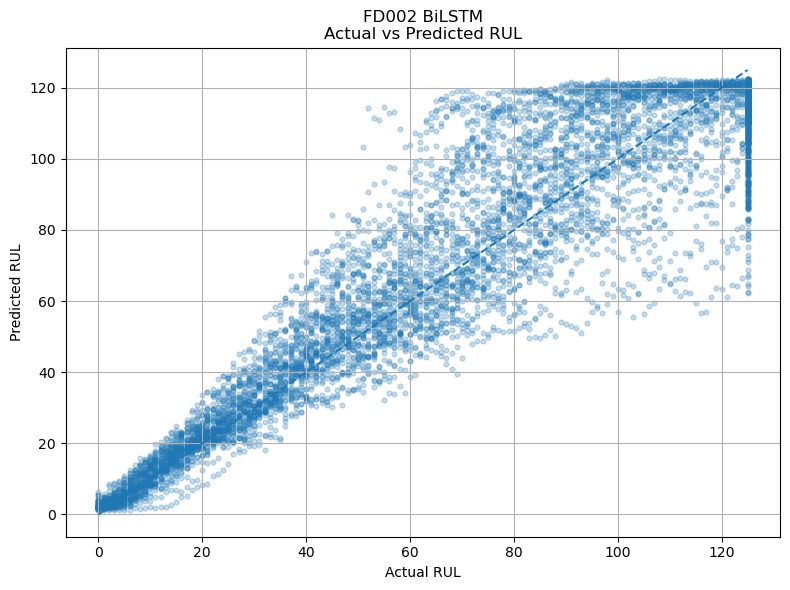

In [42]:
# ============================================================
# FD002 BiLSTM - ACTUAL VS PREDICTED RUL
# ============================================================

plt.figure(figsize=(8, 6))

plt.scatter(
    y_val_bilstm_fd002,
    pred_fd002_bilstm,
    alpha=0.25,
    s=12
)

min_value = min(
    y_val_bilstm_fd002.min(),
    pred_fd002_bilstm.min()
)

max_value = max(
    y_val_bilstm_fd002.max(),
    pred_fd002_bilstm.max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual RUL")
plt.ylabel("Predicted RUL")

plt.title(
    "FD002 BiLSTM\nActual vs Predicted RUL"
)

plt.grid()
plt.tight_layout()
plt.show()

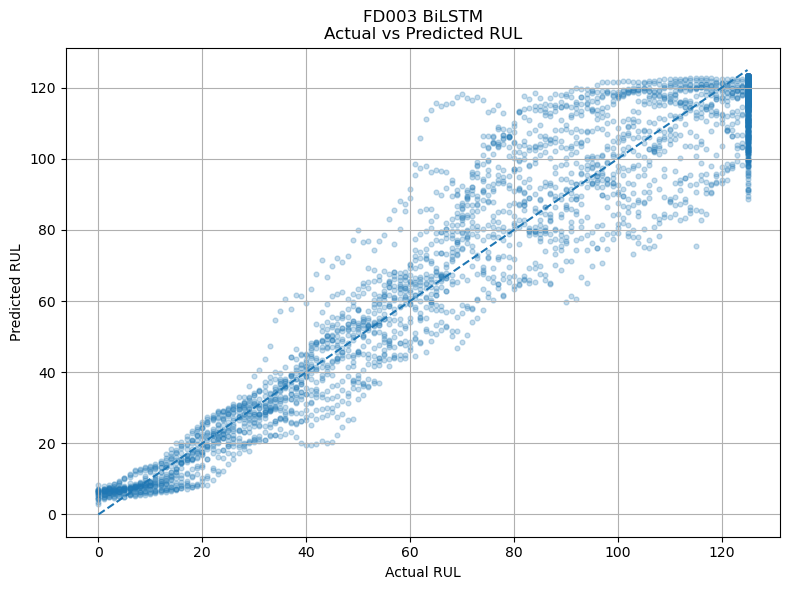

In [43]:
# ============================================================
# FD003 BiLSTM - ACTUAL VS PREDICTED RUL
# ============================================================

plt.figure(figsize=(8, 6))

plt.scatter(
    y_val_bilstm_fd003,
    pred_fd003_bilstm,
    alpha=0.25,
    s=12
)

min_value = min(
    y_val_bilstm_fd003.min(),
    pred_fd003_bilstm.min()
)

max_value = max(
    y_val_bilstm_fd003.max(),
    pred_fd003_bilstm.max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual RUL")
plt.ylabel("Predicted RUL")

plt.title(
    "FD003 BiLSTM\nActual vs Predicted RUL"
)

plt.grid()
plt.tight_layout()
plt.show()

In [44]:
# ============================================================
# TRAINING HISTORY PLOT FUNCTION
# ============================================================

def plot_training_history(
    history,
    dataset_name
):

    plt.figure(figsize=(9, 5))

    plt.plot(
        history.history["loss"],
        label="Training Loss"
    )

    plt.plot(
        history.history["val_loss"],
        label="Validation Loss"
    )

    plt.xlabel("Epoch")
    plt.ylabel("MSE Loss")

    plt.title(
        f"{dataset_name} BiLSTM Training History"
    )

    plt.legend()
    plt.grid()

    plt.tight_layout()
    plt.show()

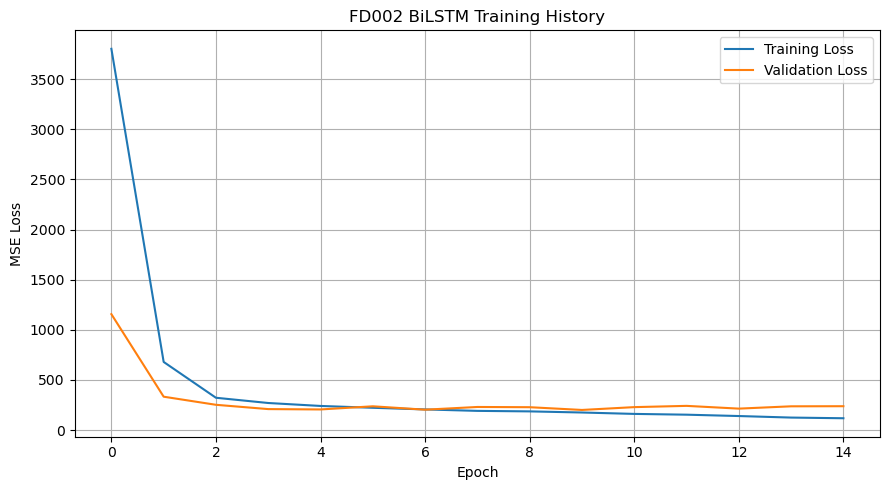

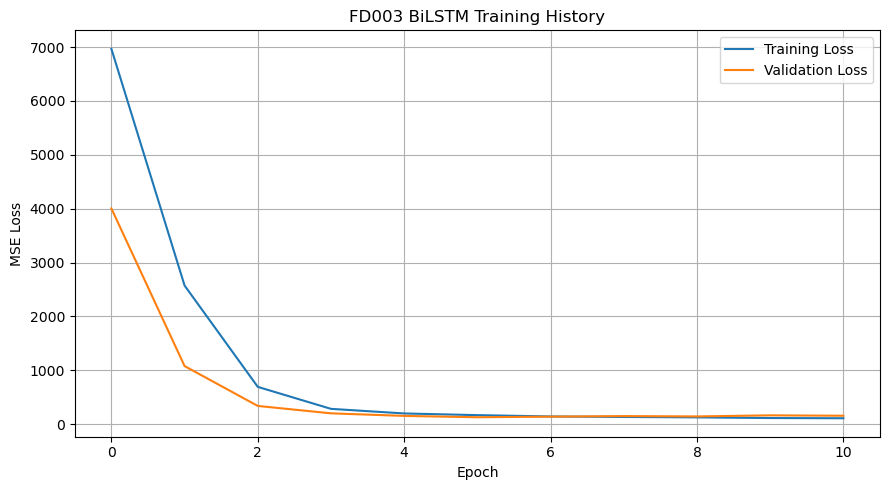

In [45]:
plot_training_history(
    history_fd002_final,
    "FD002"
)

plot_training_history(
    history_fd003_final,
    "FD003"
)

In [46]:
# ============================================================
# BiLSTM RESIDUALS
# ============================================================

fd002_bilstm_residuals = (
    y_val_bilstm_fd002
    - pred_fd002_bilstm
)

fd003_bilstm_residuals = (
    y_val_bilstm_fd003
    - pred_fd003_bilstm
)

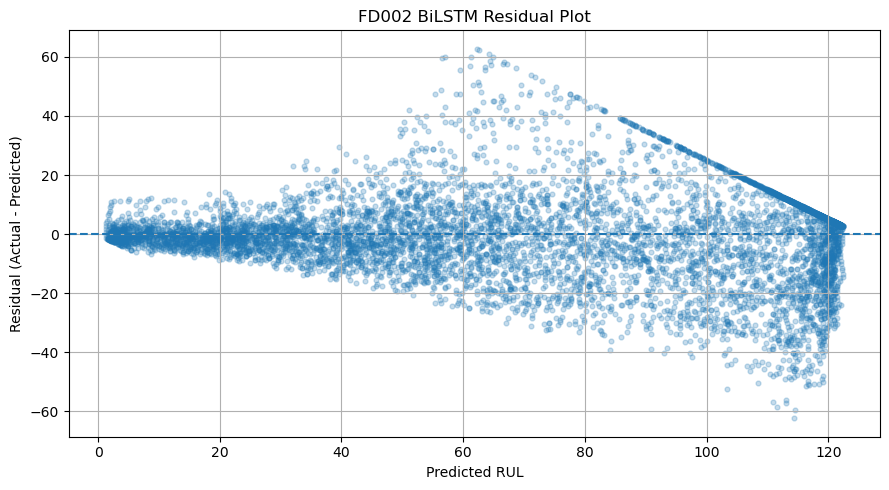

In [47]:
plt.figure(figsize=(9, 5))

plt.scatter(
    pred_fd002_bilstm,
    fd002_bilstm_residuals,
    alpha=0.25,
    s=12
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted RUL")
plt.ylabel("Residual (Actual - Predicted)")

plt.title(
    "FD002 BiLSTM Residual Plot"
)

plt.grid()
plt.tight_layout()
plt.show()

In [48]:
# ============================================================
# SAVE FINAL BiLSTM MODELS
# ============================================================

MODEL_DIR = (
    r"D:\IST\Aircraft_Engine_RUL\models"
)

os.makedirs(
    MODEL_DIR,
    exist_ok=True
)


# Keras native model format
fd002_bilstm_path = os.path.join(
    MODEL_DIR,
    "bilstm_fd002_final.keras"
)

fd003_bilstm_path = os.path.join(
    MODEL_DIR,
    "bilstm_fd003_final.keras"
)


bilstm_fd002_final.save(
    fd002_bilstm_path
)

bilstm_fd003_final.save(
    fd003_bilstm_path
)


print("✅ FD002 BiLSTM saved:")
print(fd002_bilstm_path)

print("\n✅ FD003 BiLSTM saved:")
print(fd003_bilstm_path)

✅ FD002 BiLSTM saved:
D:\IST\Aircraft_Engine_RUL\models\bilstm_fd002_final.keras

✅ FD003 BiLSTM saved:
D:\IST\Aircraft_Engine_RUL\models\bilstm_fd003_final.keras
